# Practical No. 10: One-Way ANOVA and Tukey HSD

| Student detail | Information |
|---|---|
| **Name** | Harshad Khatale |
| **PRN** | 258209007 |
| **Subject** | Data Science & Analytics |
| **Practical No.** | 10 |

## Title
**Comparing mathematics scores across parental education groups using one-way ANOVA and Tukey HSD**

## Aim
To test whether mean mathematics scores differ across more than two categorical groups and, if they do, identify the specific group pairs with significantly different means.

## Dataset and variables
This experiment uses the supplied `StudentsPerformance.csv` file (1,000 student records). The response variable is **math score** (numeric). The grouping variable is **parental level of education**, which has six categories: associate's degree, bachelor's degree, high school, master's degree, some college, and some high school. Each row represents one student.

## Theory
One-way analysis of variance (ANOVA) compares the means of a quantitative response across three or more independent groups. It partitions total variation into between-group and within-group variation. The test statistic is **F = MS between / MS within**; a sufficiently large F and a small p-value provide evidence that not all population means are equal. ANOVA indicates whether a difference exists, but not which groups differ. Tukey's Honestly Significant Difference (HSD) procedure performs all pairwise comparisons while controlling the family-wise error rate.

## Hypotheses and significance level
- **H?:** The population mean math score is the same for all six parental education groups.
- **H?:** At least one group's population mean math score differs.
- **Significance level:** ? = 0.05.

## Assumptions
The observations should be independent, scores within each group should be approximately normally distributed (especially relevant for small groups), and group variances should be reasonably similar. The notebook checks variance homogeneity with median-centered Levene's test and inspects a residual Q?Q plot. Independence is treated as a study-design assumption; it cannot be established from the score columns alone. Tukey HSD is used after a significant omnibus ANOVA.

## Procedure
Load and validate the local CSV, summarize scores by education group, visualize their distributions, check the variance assumption, run the one-way ANOVA, and apply Tukey HSD if the omnibus result is significant. The complete executable Python code and results follow.

Dataset: D:\Users\91782\Documents\WCE\V_SEM\DSA_EXPERIMENT\EXP_10\StudentsPerformance.csv
Observations: 1000 | Groups: 6 | Alpha: 0.05

Descriptive statistics by parental education:
                             count   mean    std
parental level of education                     
associate's degree             222  67.88  15.11
bachelor's degree              118  69.39  14.94
high school                    196  62.14  14.54
master's degree                 59  69.75  15.15
some college                   226  67.13  14.31
some high school               179  63.50  15.93


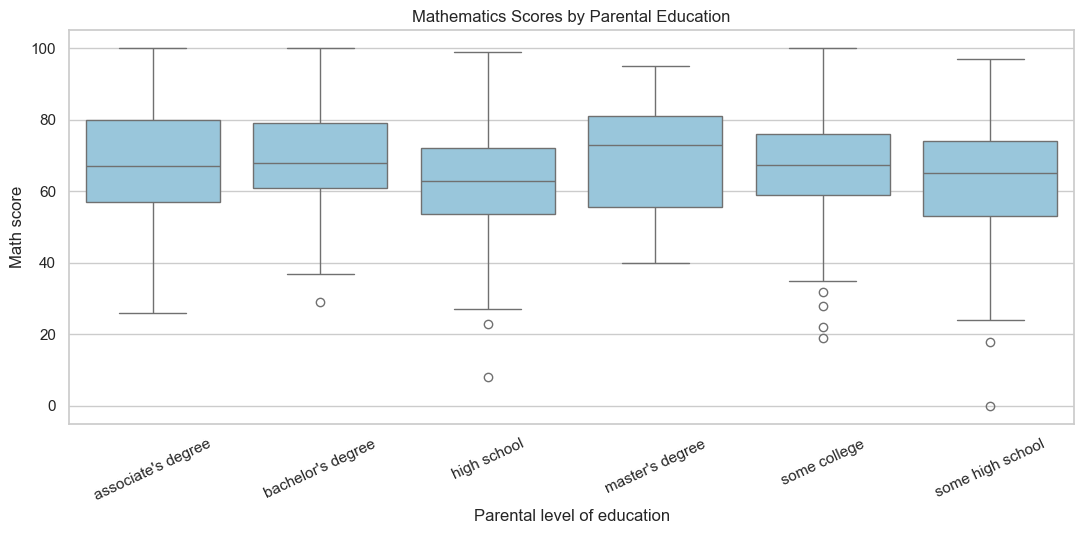


Variance homogeneity (Levene's test):
W = 0.9333, p = 0.4584
No statistically significant evidence of unequal group variances at alpha = 0.05.


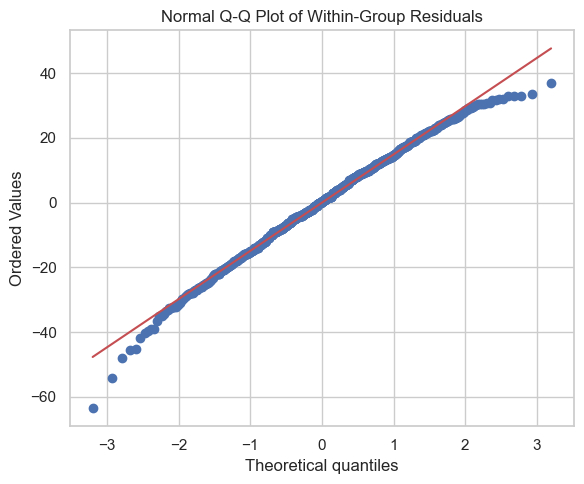


One-way ANOVA:
F(5, 994) = 6.5216
p-value = 5.59227e-06
Eta-squared = 0.0318
Decision: Reject H0. At least one mean math score differs across education groups.



Tukey HSD pairwise comparisons (meandiff = group2 - group1):
            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   1.5069 0.9503  -3.3587  6.3726  False
associate's degree       high school  -5.7451 0.0013  -9.9311 -1.5591   True
associate's degree   master's degree   1.8629 0.9578  -4.3927  8.1185  False
associate's degree      some college  -0.7546 0.9948  -4.7903  3.2812  False
associate's degree  some high school  -4.3857 0.0418   -8.676 -0.0954   True
 bachelor's degree       high school  -7.2521 0.0005 -12.2284 -2.2757   True
 bachelor's degree   master's degree   0.3559    1.0  -6.4539  7.1658  False
 bachelor's degree      some college  -2.2615 0.7676  -7.1122  2.5892  False
 bachelor's degree  some high school  -5.8926 0.0119  -10.957 -0.8282   True
       high sc

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import f_oneway, levene, probplot
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Read the dataset from the same folder as this notebook.
data_path = Path("StudentsPerformance.csv")
if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path.resolve()}")

df = pd.read_csv(data_path)
score_col = "math score"
group_col = "parental level of education"
required_cols = [score_col, group_col]
missing_cols = [column for column in required_cols if column not in df.columns]
if missing_cols:
    raise ValueError(f"Required dataset columns are missing: {missing_cols}")
if df[required_cols].isna().any().any():
    raise ValueError("Math scores and group labels must not contain missing values.")
if not pd.api.types.is_numeric_dtype(df[score_col]):
    raise TypeError(f"{score_col!r} must contain numeric values.")

alpha = 0.05
group_order = sorted(df[group_col].unique())
groups = [df.loc[df[group_col] == name, score_col] for name in group_order]
if len(groups) < 3 or any(len(group) < 2 for group in groups):
    raise ValueError("ANOVA requires at least three groups with two or more observations each.")

print(f"Dataset: {data_path.resolve()}")
print(f"Observations: {len(df)} | Groups: {len(groups)} | Alpha: {alpha}")
print("\nDescriptive statistics by parental education:")
summary = df.groupby(group_col)[score_col].agg(["count", "mean", "std"]).reindex(group_order)
print(summary.round(2).to_string())

# Visual comparison of the group distributions.
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df, x=group_col, y=score_col, order=group_order, ax=ax, color="#8ecae6")
ax.set_title("Mathematics Scores by Parental Education")
ax.set_xlabel("Parental level of education")
ax.set_ylabel("Math score")
ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()

# Check the equal-variance assumption using median-centered Levene's test.
levene_stat, levene_p = levene(*groups, center="median")
print("\nVariance homogeneity (Levene's test):")
print(f"W = {levene_stat:.4f}, p = {levene_p:.4f}")
if levene_p >= alpha:
    print("No statistically significant evidence of unequal group variances at alpha = 0.05.")
else:
    print("Group variances differ significantly; interpret classical ANOVA/Tukey results cautiously.")

# Inspect the distribution of residuals from the one-way group-means model.
residuals = df[score_col] - df.groupby(group_col)[score_col].transform("mean")
fig, ax = plt.subplots(figsize=(6, 5))
probplot(residuals, dist="norm", plot=ax)
ax.set_title("Normal Q-Q Plot of Within-Group Residuals")
fig.tight_layout()
plt.show()

# One-way ANOVA: H0 says all six population group means are equal.
anova_result = f_oneway(*groups)
number_of_groups = len(groups)
df_between = number_of_groups - 1
df_within = len(df) - number_of_groups
overall_mean = df[score_col].mean()
ss_between = sum(len(group) * (group.mean() - overall_mean) ** 2 for group in groups)
ss_total = ((df[score_col] - overall_mean) ** 2).sum()
eta_squared = ss_between / ss_total
print("\nOne-way ANOVA:")
print(f"F({df_between}, {df_within}) = {anova_result.statistic:.4f}")
print(f"p-value = {anova_result.pvalue:.6g}")
print(f"Eta-squared = {eta_squared:.4f}")

if anova_result.pvalue < alpha:
    print("Decision: Reject H0. At least one mean math score differs across education groups.")

    # Tukey HSD identifies the pairs responsible for the omnibus difference.
    tukey = pairwise_tukeyhsd(endog=df[score_col], groups=df[group_col], alpha=alpha)
    tukey_rows = tukey.summary().data
    tukey_table = pd.DataFrame(tukey_rows[1:], columns=tukey_rows[0])
    print("\nTukey HSD pairwise comparisons (meandiff = group2 - group1):")
    print(tukey.summary())

    significant_pairs = tukey_table[
        tukey_table["reject"].astype(str).str.lower().eq("true")
    ]
    print("\nPairs significantly different at alpha = 0.05:")
    if significant_pairs.empty:
        print("No individual pair was significant after Tukey adjustment.")
    else:
        print(significant_pairs.to_string(index=False))
        print("\nConclusion:")
        for _, row in significant_pairs.iterrows():
            direction = "higher" if float(row["meandiff"]) > 0 else "lower"
            print(
                f"- {row['group2']} has a {direction} mean math score than {row['group1']} "
                f"(difference {float(row['meandiff']):.2f} points, "
                f"Tukey-adjusted p = {float(row['p-adj']):.4g})."
            )
else:
    print("Decision: Fail to reject H0. There is insufficient evidence of different group means.")
    print("Tukey HSD was not run because the omnibus ANOVA was not significant.")

## Interpretation and conclusion
Use the ANOVA p-value at ? = 0.05 to decide whether there is evidence that the six population means are all equal. When the omnibus test is significant, use the Tukey HSD table's adjusted p-values and `reject` column to identify the specific differing pairs. A positive Tukey `meandiff` means the second group has the higher sample mean; a negative value means it has the lower sample mean. The printed conclusion reports the significant pairs and score differences in points.

These are associations in the supplied student dataset; the results do not establish that parental education causes a difference in math scores.